In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay
)

RANDOM_STATE = 42
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("Module 3 Project Data.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 5)


,Index,Employed,Bank Balance,Annual Salary,Defaulted?
0,1,1,8754.36,532339.56,0
1,2,0,9806.16,145273.56,0
2,3,1,12882.60,381205.68,0
3,4,1,6351.00,428453.88,0
4,5,1,9427.92,461562.00,0


In [3]:
print("Columns:", df.columns.tolist())

df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.describe())

Columns: ['Index', 'Employed', 'Bank Balance', 'Annual Salary', 'Defaulted?']
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Index          10000 non-null  int64  
 1   Employed       10000 non-null  int64  
 2   Bank Balance   10000 non-null  float64
 3   Annual Salary  10000 non-null  float64
 4   Defaulted?     10000 non-null  int64  
dtypes: float64(2), int64(3)
memory usage: 390.8 KB

Missing values:
Index            0
Employed         0
Bank Balance     0
Annual Salary    0
Defaulted?       0
dtype: int64

Duplicate rows: 0


,Index,Employed,Bank Balance,Annual Salary,Defaulted?
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,0.705600,10024.498524,402203.782224,0.033300
std,2886.89568,0.455795,5804.579486,160039.674988,0.179428
min,1.00000,0.000000,0.000000,9263.640000,0.000000
25%,2500.75000,0.000000,5780.790000,256085.520000,0.000000
50%,5000.50000,1.000000,9883.620000,414631.740000,0.000000
75%,7500.25000,1.000000,13995.660000,525692.760000,0.000000
max,10000.00000,1.000000,31851.840000,882650.760000,1.000000


In [4]:
df = df.drop(columns=["Index"], errors="ignore")

features = ["Employed", "Bank Balance", "Annual Salary"]
target = "Defaulted?"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)

for col in features:
    df[col] = df[col].fillna(df[col].median())

df = df.dropna(subset=[target])
df = df[df[target].isin([0, 1])].copy()
df[target] = df[target].astype(int)

print("Cleaned dataset:", df.shape)
display(df.head())

Cleaned dataset: (10000, 4)


,Employed,Bank Balance,Annual Salary,Defaulted?
0,1,8754.36,532339.56,0
1,0,9806.16,145273.56,0
2,1,12882.60,381205.68,0
3,1,6351.00,428453.88,0
4,1,9427.92,461562.00,0


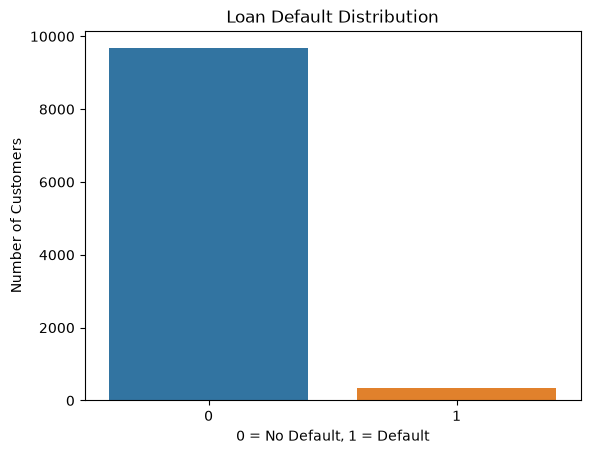

In [5]:
sns.countplot(data=df, x="Defaulted?", hue="Defaulted?", legend=False)

plt.title("Loan Default Distribution")
plt.xlabel("0 = No Default, 1 = Default")
plt.ylabel("Number of Customers")
plt.show()

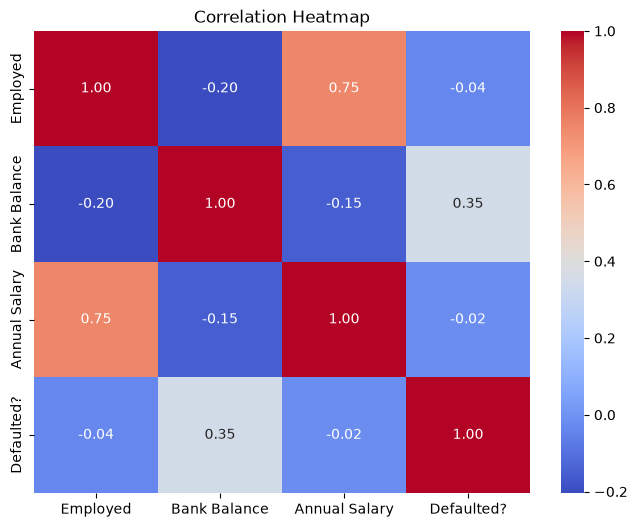

In [6]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[features + [target]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [7]:
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


In [8]:
scale_pos_weight = (
    (y_train == 0).sum() / max((y_train == 1).sum(), 1)
)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

print("All 4 models are ready!")

All 4 models are ready!


In [9]:
for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Training: Logistic Regression
Logistic Regression trained successfully!
Training: Random Forest
Random Forest trained successfully!
Training: XGBoost
XGBoost trained successfully!
Training: SVM


d:\Projects Practice\DSML MINI PROJECTS\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM trained successfully!


In [10]:
results = []
predictions = {}
probabilities = {}

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8550,0.1730,0.8806,0.2892,0.9487
1,XGBoost,0.8885,0.2023,0.7910,0.3222,0.9374
2,SVM,0.8410,0.1617,0.8955,0.2740,0.9152
3,Random Forest,0.9615,0.4405,0.5522,0.4901,0.9053


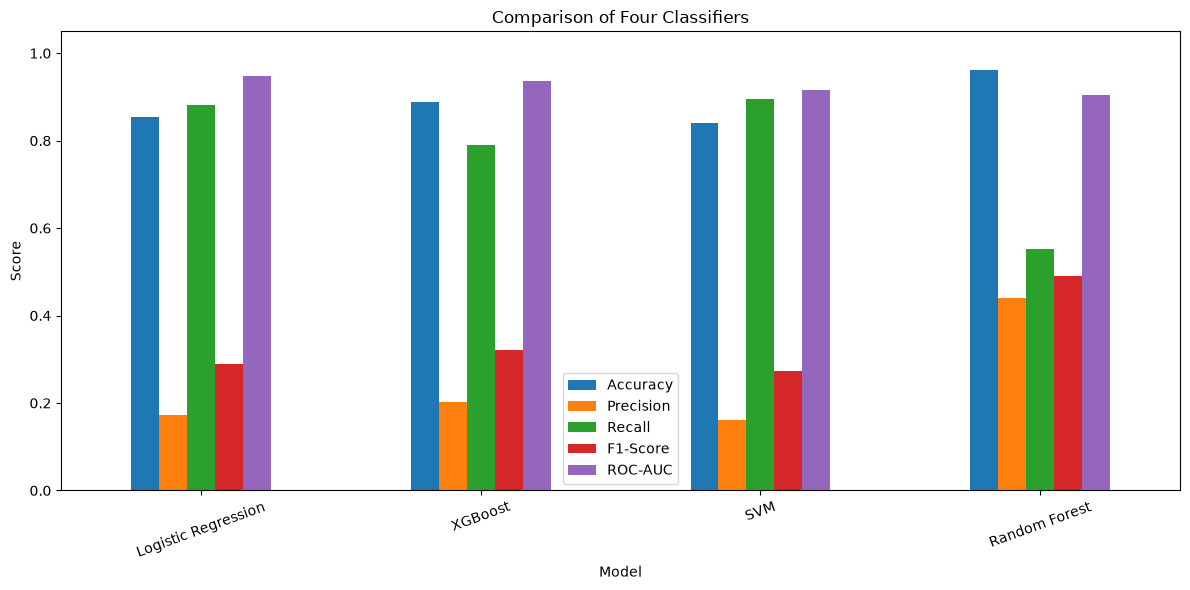

In [11]:
metrics = [
    "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05)
)

plt.title("Comparison of Four Classifiers")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

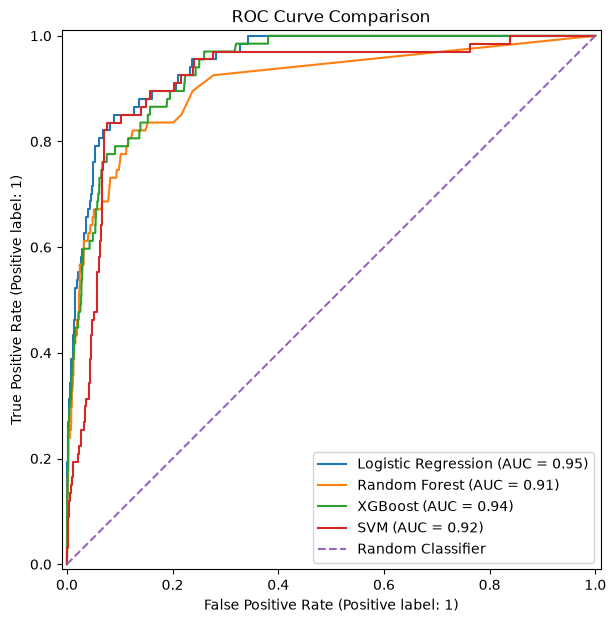

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))

for name in models:
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities[name],
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [13]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("ROC-AUC:", round(results_df.iloc[0]["ROC-AUC"], 4))

Best Model: Logistic Regression
ROC-AUC: 0.9487


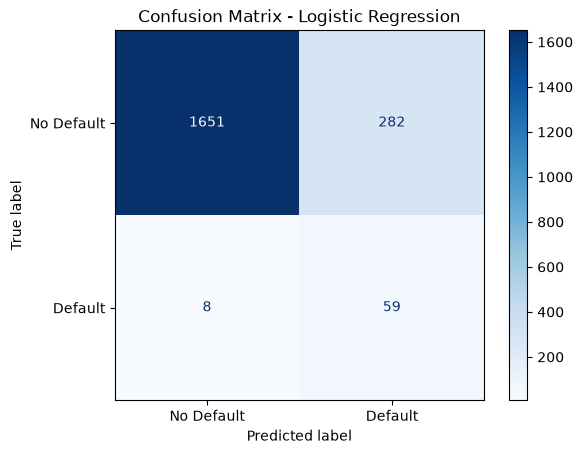

In [14]:
best_predictions = predictions[best_model_name]

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"]
)

disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

In [15]:
print(classification_report(
    y_test,
    best_predictions,
    target_names=["No Default", "Default"],
    zero_division=0
))

              precision    recall  f1-score   support

  No Default       1.00      0.85      0.92      1933
     Default       0.17      0.88      0.29        67

    accuracy                           0.85      2000
   macro avg       0.58      0.87      0.60      2000
weighted avg       0.97      0.85      0.90      2000



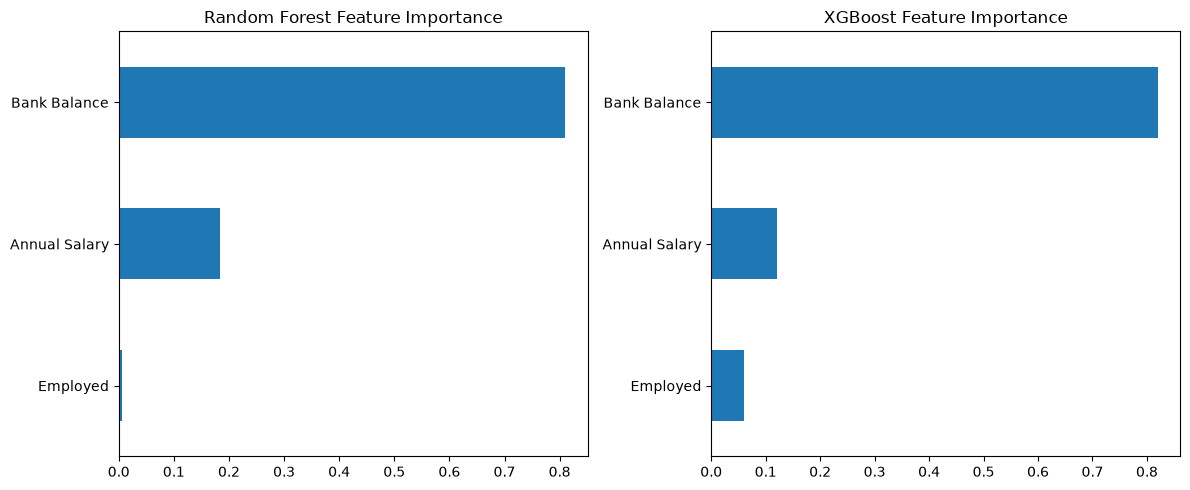

Random Forest ranking:
Bank Balance     0.810099
Annual Salary    0.183563
Employed         0.006338
dtype: float64

XGBoost ranking:
Bank Balance     0.819675
Annual Salary    0.120934
Employed         0.059391
dtype: float32


In [16]:
rf_importance = pd.Series(
    models["Random Forest"].feature_importances_,
    index=features
).sort_values()

xgb_importance = pd.Series(
    models["XGBoost"].feature_importances_,
    index=features
).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

rf_importance.plot(kind="barh", ax=axes[0])
axes[0].set_title("Random Forest Feature Importance")

xgb_importance.plot(kind="barh", ax=axes[1])
axes[1].set_title("XGBoost Feature Importance")

plt.tight_layout()
plt.show()

print("Random Forest ranking:")
print(rf_importance.sort_values(ascending=False))

print("\nXGBoost ranking:")
print(xgb_importance.sort_values(ascending=False))

In [17]:
new_customer = pd.DataFrame({
    "Employed": [1],
    "Bank Balance": [5000.0],
    "Annual Salary": [250000.0]
})

prediction = best_model.predict(new_customer)[0]
probability = best_model.predict_proba(new_customer)[0, 1]

print("Selected model:", best_model_name)
print("Prediction:", "Default" if prediction == 1 else "No Default")
print(f"Estimated default probability: {probability:.2%}")

Selected model: Logistic Regression
Prediction: No Default
Estimated default probability: 0.68%


In [18]:
joblib.dump(best_model, "best_loan_default_model.pkl")

results_df.to_csv("model_comparison_results.csv", index=False)

print("Model saved successfully!")
print("Comparison results saved successfully!")

Model saved successfully!
Comparison results saved successfully!
